In [77]:
#próbka po plazmie tlenowo-argonowej 0 i 2 s
from funkcje.Lorentz2Raman import *

In [78]:
plt.rcParams.update(
        {
            "axes.labelsize":18,
            "xtick.labelsize":16,
            "ytick.labelsize":16,
            "legend.fontsize":16,
            "figure.autolayout":True,
        }
    )

In [79]:
#import wszystkich mapek dla próbki 5

BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka5" / "dane_pomiarowe"

rs_PL_0s, I_PL_0s = importMap(sciezka/"WSe2_mapa_PL_5_0s.txt")
rs_PL_2s, I_PL_2s = importMap(sciezka/"WSe2_mapa_PL_5_2s.txt")


rs_Raman_0s, I_Raman_0s = importMap(sciezka/"WSe2_mapa_Raman_5_0s.txt")
rs_Raman_2s, I_Raman_2s = importMap(sciezka/"WSe2_mapa_Raman_5_2s.txt")

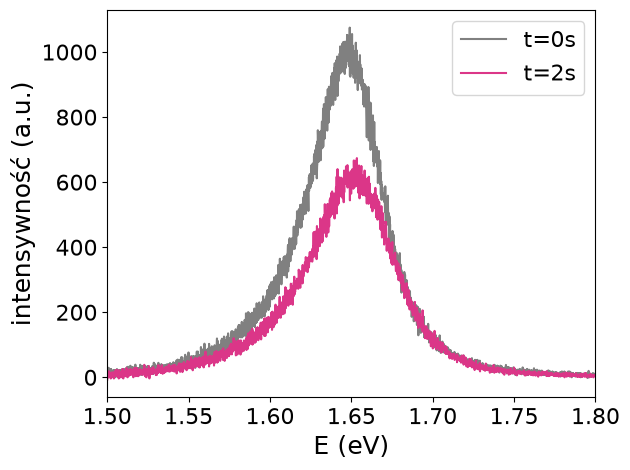

In [80]:
#testowe pojedyncze widma PL, żebym wiedziała co dopasować 

plt.plot(rs_PL_0s[10], I_PL_0s[8],label="t=0s",color='gray')
plt.plot(rs_PL_2s[10], I_PL_2s[11],label="t=2s",color="#DB3688")
plt.xlabel(r"E (eV)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(1.5,1.8)

BASE = Path().resolve()
sciezka=BASE/"analiza"/"próbka5"/"wykresy"
plt.savefig(sciezka/'PL_2s.png')

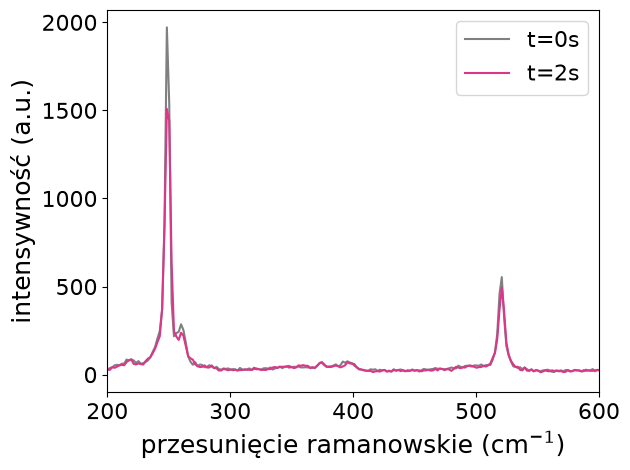

In [81]:
# testowe pojedyncze widma ramana, żebym wiedziała co dopasować 

plt.plot(rs_Raman_0s[10], I_Raman_0s[10],label="t=0s",color='gray')
plt.plot(rs_Raman_2s[10], I_Raman_2s[10],label="t=2s",color="#DB3688")
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(200,600)
plt.savefig(sciezka/'Raman_2s.png')

In [82]:
#dopasowanie piku PL

centers_PL_0s, fwhms_PL_0s, intensities_PL_0s = lorentz2map(rs_PL_0s, I_PL_0s, xmin=1.5, xmax=1.7)
centers_PL_2s, fwhms_PL_2s, intensities_PL_2s = lorentz2map(rs_PL_2s, I_PL_2s, xmin=1.55, xmax=1.75)

In [83]:
#dopasowanie piku E i A

centers_Raman_EA_0s, fwhms_Raman_EA_0s, intensities_Raman_EA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=240, xmax=255)
centers_Raman_EA_2s, fwhms_Raman_EA_2s, intensities_Raman_EA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=240, xmax=255)

In [84]:
#usunięcie punktów mocno odstających - krawędzi monowarswty/samego podłoża = dla widm ramaniowskich niepewnosc fwhm w granicach warstosci
maska_Raman_EA_0s=(fwhms_Raman_EA_0s>=0) &(fwhms_Raman_EA_0s<=16)
fwhms_Raman_EA_0s=fwhms_Raman_EA_0s[maska_Raman_EA_0s]
centers_Raman_EA_0s=centers_Raman_EA_0s[maska_Raman_EA_0s]
intensities_Raman_EA_0s=intensities_Raman_EA_0s[maska_Raman_EA_0s]

maska_Raman_EA_2s=(fwhms_Raman_EA_2s>=0) &(fwhms_Raman_EA_2s<=20)
fwhms_Raman_EA_2s=fwhms_Raman_EA_2s[maska_Raman_EA_2s]
centers_Raman_EA_2s=centers_Raman_EA_2s[maska_Raman_EA_2s]
intensities_Raman_EA_2s=intensities_Raman_EA_2s[maska_Raman_EA_2s]


In [85]:
#dopasowanie piku 2LA(M)

centers_Raman_LA_0s, fwhms_Raman_LA_0s, intensities_Raman_LA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=255, xmax=265)
centers_Raman_LA_2s, fwhms_Raman_LA_2s, intensities_Raman_LA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=255, xmax=265)

In [86]:
maska_Raman_LA_0s=(fwhms_Raman_LA_0s>=0) &(fwhms_Raman_LA_0s<=25)
fwhms_Raman_LA_0s=fwhms_Raman_LA_0s[maska_Raman_LA_0s]
centers_Raman_LA_0s=centers_Raman_LA_0s[maska_Raman_LA_0s]
intensities_Raman_LA_0s=intensities_Raman_LA_0s[maska_Raman_LA_0s]

maska_Raman_LA_2s=(fwhms_Raman_LA_2s>=0) &(fwhms_Raman_LA_2s<=25)
fwhms_Raman_LA_2s=fwhms_Raman_LA_2s[maska_Raman_LA_2s]
centers_Raman_LA_2s=centers_Raman_LA_2s[maska_Raman_LA_2s]
intensities_Raman_LA_2s=intensities_Raman_LA_2s[maska_Raman_LA_2s]

In [87]:
mu_centers_PL_0s, sigma_centers_PL_0s = norm.fit(centers_PL_0s)
print(f"{mu_centers_PL_0s} ± {sigma_centers_PL_0s}")
x_centers_PL_0s,y_centers_PL_0s=gauss(mu_centers_PL_0s,sigma_centers_PL_0s)

mu_centers_PL_2s, sigma_centers_PL_2s = norm.fit(centers_PL_2s)
print(f"{mu_centers_PL_2s} ± {sigma_centers_PL_2s}")
x_centers_PL_2s,y_centers_PL_2s=gauss(mu_centers_PL_2s,sigma_centers_PL_2s)

1.6462384514672932 ± 0.0021791869605702393
1.6443900952485446 ± 0.003126399329564242


In [88]:
mu_intensities_PL_0s, sigma_intensities_PL_0s = norm.fit(intensities_PL_0s)
print(f"{mu_intensities_PL_0s} ± {sigma_intensities_PL_0s}")
x_intensities_PL_0s,y_intensities_PL_0s=gauss(mu_intensities_PL_0s,sigma_intensities_PL_0s)


mu_intensities_PL_2s, sigma_intensities_PL_2s = norm.fit(intensities_PL_2s)
print(f"{mu_intensities_PL_2s} ± {sigma_intensities_PL_2s}")
x_intensities_PL_2s,y_intensities_PL_2s=gauss(mu_intensities_PL_2s,sigma_intensities_PL_2s)

831.0212432910658 ± 85.04794629603875
567.3634904001983 ± 91.41391508475057


In [89]:
mu_fwhms_PL_0s, sigma_fwhms_PL_0s = norm.fit(fwhms_PL_0s)
print(f"{mu_fwhms_PL_0s} ± {sigma_fwhms_PL_0s}")
x_fwhms_PL_0s,y_fwhms_PL_0s=gauss(mu_fwhms_PL_0s,sigma_fwhms_PL_0s)


mu_fwhms_PL_2s, sigma_fwhms_PL_2s = norm.fit(fwhms_PL_2s)
print(f"{mu_fwhms_PL_2s} ± {sigma_fwhms_PL_2s}")
x_fwhms_PL_2s,y_fwhms_PL_2s=gauss(mu_fwhms_PL_2s,sigma_fwhms_PL_2s)

0.05127571157152198 ± 0.002031220321416229
0.05323328664849525 ± 0.001563752888688943


In [90]:
mu_centers_Raman_EA_0s, sigma_centers_Raman_EA_0s = norm.fit(centers_Raman_EA_0s)
print(f"{mu_centers_Raman_EA_0s} ± {sigma_centers_Raman_EA_0s}")
x_centers_Raman_EA_0s,y_centers_Raman_EA_0s=gauss(mu_centers_Raman_EA_0s,sigma_centers_Raman_EA_0s)

mu_centers_Raman_EA_2s, sigma_centers_Raman_EA_2s = norm.fit(centers_Raman_EA_2s)
print(f"{mu_centers_Raman_EA_2s} ± {sigma_centers_Raman_EA_2s}")
x_centers_Raman_EA_2s,y_centers_Raman_EA_2s=gauss(mu_centers_Raman_EA_2s,sigma_centers_Raman_EA_2s)

249.025317463379 ± 0.060464086874307134
249.3954761013363 ± 0.0818733718251882


In [91]:
mu_intensities_Raman_EA_0s, sigma_intensities_Raman_EA_0s = norm.fit(intensities_Raman_EA_0s)
print(f"{mu_intensities_Raman_EA_0s} ± {sigma_intensities_Raman_EA_0s}")
x_intensities_Raman_EA_0s,y_intensities_Raman_EA_0s=gauss(mu_intensities_Raman_EA_0s,sigma_intensities_Raman_EA_0s)

mu_intensities_Raman_EA_2s, sigma_intensities_Raman_EA_2s = norm.fit(intensities_Raman_EA_2s)
print(f"{mu_intensities_Raman_EA_2s} ± {sigma_intensities_Raman_EA_2s}")
x_intensities_Raman_EA_2s,y_intensities_Raman_EA_2s=gauss(mu_intensities_Raman_EA_2s,sigma_intensities_Raman_EA_2s)

2173.033819896548 ± 57.540736147432256
1827.4144437152763 ± 61.322204235959084


In [92]:
mu_fwhms_Raman_EA_0s, sigma_fwhms_Raman_EA_0s = norm.fit(fwhms_Raman_EA_0s)
print(f"{mu_fwhms_Raman_EA_0s} ± {sigma_fwhms_Raman_EA_0s}")
x_fwhms_Raman_EA_0s,y_fwhms_Raman_EA_0s=gauss(mu_fwhms_Raman_EA_0s,sigma_fwhms_Raman_EA_0s)

mu_fwhms_Raman_EA_2s, sigma_fwhms_Raman_EA_2s = norm.fit(fwhms_Raman_EA_2s)
print(f"{mu_fwhms_Raman_EA_2s} ± {sigma_fwhms_Raman_EA_2s}")
x_fwhms_Raman_EA_2s,y_fwhms_Raman_EA_2s=gauss(mu_fwhms_Raman_EA_2s,sigma_fwhms_Raman_EA_2s)

3.98297659085739 ± 0.11391758397831388
4.729907640188226 ± 0.1494616693260498


In [93]:
mu_centers_Raman_LA_0s, sigma_centers_Raman_LA_0s = norm.fit(centers_Raman_LA_0s)
print(f"{mu_centers_Raman_LA_0s} ± {sigma_centers_Raman_LA_0s}")
x_centers_Raman_LA_0s,y_centers_Raman_LA_0s=gauss(mu_centers_Raman_LA_0s,sigma_centers_Raman_LA_0s)

mu_centers_Raman_LA_2s, sigma_centers_Raman_LA_2s = norm.fit(centers_Raman_LA_2s)
print(f"{mu_centers_Raman_LA_2s} ± {sigma_centers_Raman_LA_2s}")
x_centers_Raman_LA_2s,y_centers_Raman_LA_2s=gauss(mu_centers_Raman_LA_2s,sigma_centers_Raman_LA_2s)

259.5474483592435 ± 0.16663976509753822
259.7391033190099 ± 0.5798700521234681


In [94]:
mu_intensities_Raman_LA_0s, sigma_intensities_Raman_LA_0s = norm.fit(intensities_Raman_LA_0s)
print(f"{mu_intensities_Raman_LA_0s} ± {sigma_intensities_Raman_LA_0s}")
x_intensities_Raman_LA_0s,y_intensities_Raman_LA_0s=gauss(mu_intensities_Raman_LA_0s,sigma_intensities_Raman_LA_0s)

mu_intensities_Raman_LA_2s, sigma_intensities_Raman_LA_2s = norm.fit(intensities_Raman_LA_2s)
print(f"{mu_intensities_Raman_LA_2s} ± {sigma_intensities_Raman_LA_2s}")
x_intensities_Raman_LA_2s,y_intensities_Raman_LA_2s=gauss(mu_intensities_Raman_LA_2s,sigma_intensities_Raman_LA_2s)

284.9463796677988 ± 12.904057092462931
260.95153096635426 ± 9.397866157124588


In [95]:
mu_fwhms_Raman_LA_0s, sigma_fwhms_Raman_LA_0s = norm.fit(fwhms_Raman_LA_0s)
print(f"{mu_fwhms_Raman_LA_0s} ± {sigma_fwhms_Raman_LA_0s}")
x_fwhms_Raman_LA_0s,y_fwhms_Raman_LA_0s=gauss(mu_fwhms_Raman_LA_0s,sigma_fwhms_Raman_LA_0s)

mu_fwhms_Raman_LA_2s, sigma_fwhms_Raman_LA_2s = norm.fit(fwhms_Raman_LA_2s)
print(f"{mu_fwhms_Raman_LA_2s} ± {sigma_fwhms_Raman_LA_2s}")
x_fwhms_Raman_LA_2s,y_fwhms_Raman_LA_2s=gauss(mu_fwhms_Raman_LA_2s,sigma_fwhms_Raman_LA_2s)

12.21208553040385 ± 1.3033690529740796
13.757992506973252 ± 0.9388904996377405
